# Complete the Look: CNN vs. Transformer for Fashion Recommendation on Pinterest

**Question.** A user is looking at an outfit photo (a *scene*). Which *product* (shoes, bag, ...) goes with it?

**What we compare.** Two image encoders inside the *same* recommender:

| | Model A | Model B |
|---|---|---|
| Image encoder | **CNN** (ResNet-101) | **Transformer** (ViT-B/32) |
| Pre-training | CLIP (OpenAI, 400M image–text pairs) | CLIP (LAION-2B) |
| Recommender on top | Visual BPR (identical) | Visual BPR (identical) |

Model A (CNN) is implemented below; Model B (Transformer) is a template for the teammate, with its features already extracted. Both plug into the same evaluation, so the comparison is mainly about the **architecture**. (Their pre-training data differs; we picked the light CNN to keep compute low on a laptop.)

**Outline:** 1. Task · 2. Data · 3. Baselines · 4. Models A & B · 5. Results · 6. Error analysis · 7. Related work

## 1. Predictive task

* **Input:** a scene photo with the target product **greyed out** (otherwise the model could just "see" the answer), and the product's category.
* **Output:** a ranking of 100 candidate products of that category: 1 true product + 99 random negatives.
* **Metrics:** **AUC** (quality of the whole ranking), **Hit@10** (is the true product in the top 10?), and **NDCG@10** (the higher it is ranked, the better).
* **Validity:** we split by scene, so every test photo is new. The negatives come from the same category, so the model has to judge *style*, not just *category*.

In [1]:
import json, os, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams['figure.dpi'] = 110

## 2. Data

**Pinterest Fashion Compatibility** (Kang et al., *Complete the Look*, CVPR 2019; https://github.com/kang205/STL-Dataset).
Each record says that a product appears in a scene photo, and gives its bounding box. The labels come from Pinterest's "Shop the Look" annotations.
`prepare_data.py` downloads the images and turns each one into a feature vector with the image encoders; this notebook only loads those vectors.

In [2]:
pairs = pd.DataFrame([json.loads(l) for l in open('data/fashion.json')])
cat_full = json.load(open('data/fashion-cat.json'))
pairs['category'] = pairs['product'].map(lambda p: cat_full[p].split('|')[-1])

n_s, n_p = pairs.scene.nunique(), pairs['product'].nunique()
pd.Series({'pairs': len(pairs), 'scenes': n_s, 'products': n_p, 'categories': pairs.category.nunique(),
           'products per scene': round(len(pairs) / n_s, 2),
           'products that appear in only 1 scene': f"{(pairs['product'].value_counts() == 1).mean():.0%}"}).to_frame('value')

,value
pairs,72198
scenes,29438
products,38111
categories,10
products per scene,2.45
products that appear in only 1 scene,70%


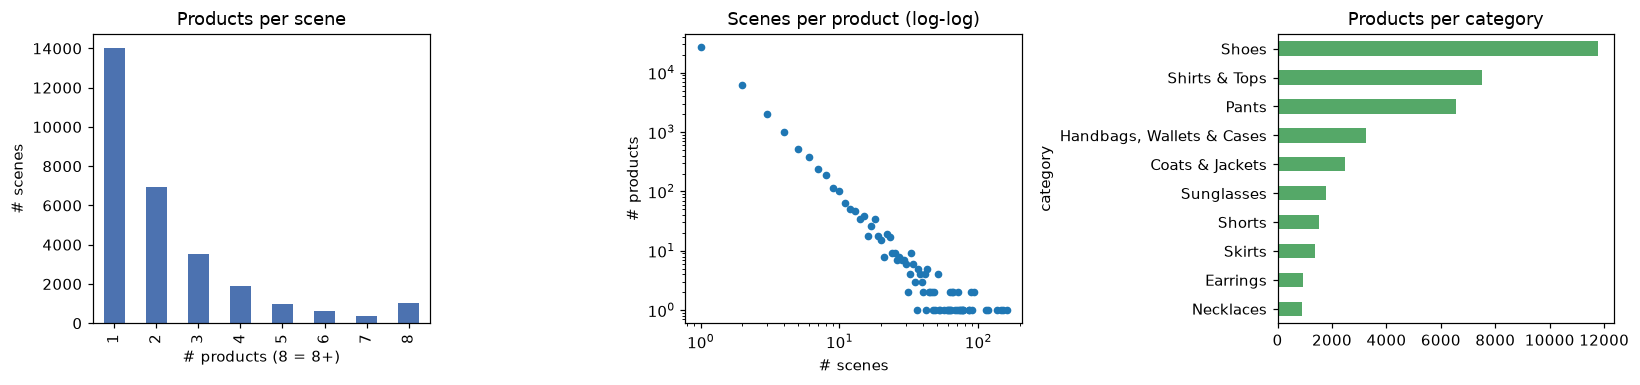

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
pairs.groupby('scene').size().clip(upper=8).value_counts().sort_index().plot.bar(ax=ax[0], color='#4C72B0')
ax[0].set(title='Products per scene', xlabel='# products (8 = 8+)', ylabel='# scenes')
vc = pairs['product'].value_counts().value_counts().sort_index()
ax[1].loglog(vc.index, vc.values, 'o', ms=4); ax[1].set(title='Scenes per product (log-log)', xlabel='# scenes', ylabel='# products')
pairs.drop_duplicates('product').category.value_counts().plot.barh(ax=ax[2], color='#55A868')
ax[2].set(title='Products per category'); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

**Takeaway:** the data is extremely sparse, and 70% of products appear in only one scene. Collaborative filtering by ID has almost nothing to learn from, so we need the **images**.

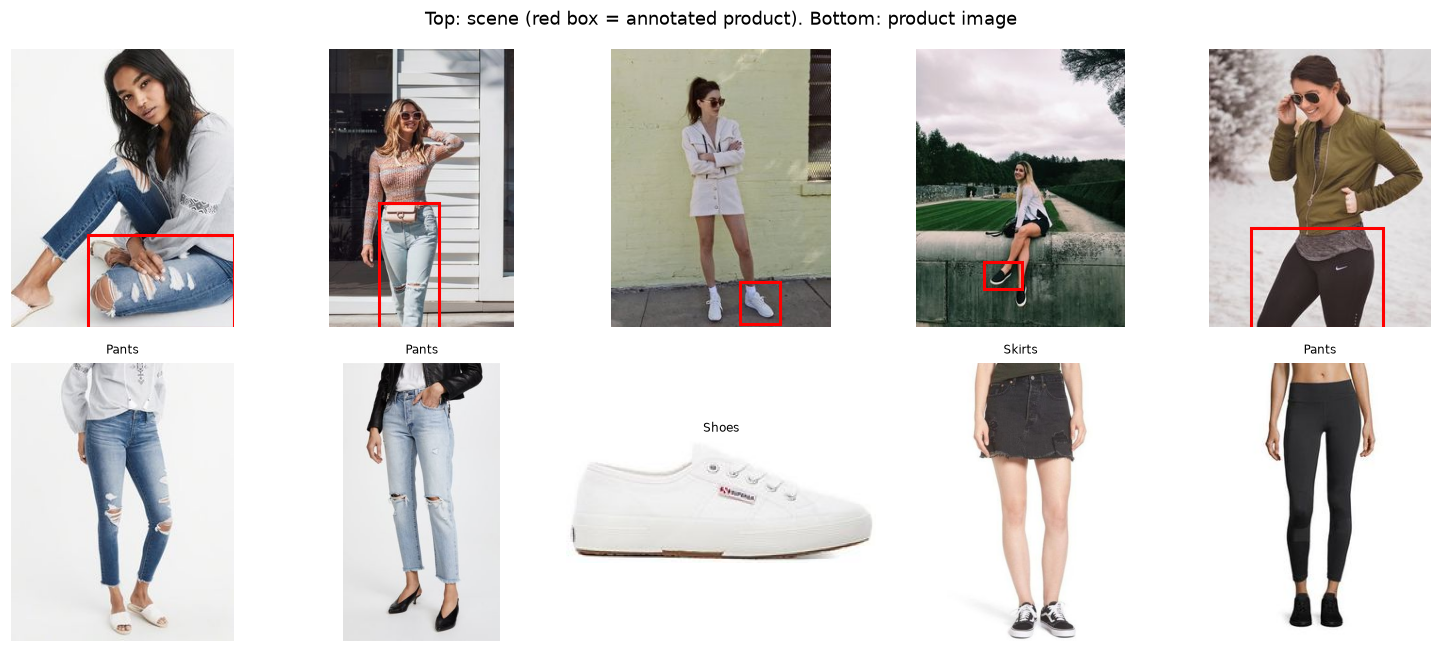

In [4]:
def img(sig):
    p = f'data/images/{sig}.jpg'
    return Image.open(p).convert('RGB') if os.path.exists(p) else Image.new('RGB', (236, 236), 'white')

fig, ax = plt.subplots(2, 5, figsize=(14, 6))
for i, (_, r) in enumerate(pairs.sample(5, random_state=1).iterrows()):
    im = img(r.scene); w, h = im.size; l, t, rr, b = r.bbox
    ax[0, i].imshow(im); ax[0, i].add_patch(plt.Rectangle((l*w, t*h), (rr-l)*w, (b-t)*h, fill=False, ec='red', lw=2))
    ax[1, i].imshow(img(r['product'])); ax[1, i].set_title(r.category, fontsize=8)
    ax[0, i].axis('off'); ax[1, i].axis('off')
plt.suptitle('Top: scene (red box = annotated product). Bottom: product image'); plt.tight_layout(); plt.show()

### Split, negatives, and the evaluation function
Scenes are split 80/10/10 into train / valid / test. Each held-out pair gets 99 fixed negatives from the same category, so every model is scored on exactly the same candidates.

In [5]:
idx = json.load(open('data/feat_index.json'))
pid = {p: i for i, p in enumerate(idx['products'])}
pairs['p'], pairs['row'] = pairs['product'].map(pid), np.arange(len(pairs))

rng = np.random.default_rng(SEED)
scenes = pairs.scene.unique().tolist(); rng.shuffle(scenes); n = len(scenes)
split = {s: 'train' if i < .8 * n else 'valid' if i < .9 * n else 'test' for i, s in enumerate(scenes)}
pairs['split'] = pairs.scene.map(split)
train, valid, test = (pairs[pairs.split == k].reset_index(drop=True) for k in ['train', 'valid', 'test'])

prod_cat = pairs.drop_duplicates('p').set_index('p').category
cat_products = {c: g.index.values for c, g in prod_cat.groupby(prod_cat)}
train_products = set(train.p)
train_cat_products = {c: np.array([p for p in v if p in train_products]) for c, v in cat_products.items()}
scene_pos = pairs.groupby('scene').p.apply(set).to_dict()

def sample_negatives(df, seed, k=99):
    r = np.random.default_rng(seed)
    return np.array([[x for x in r.choice(cat_products[c], 3 * k) if x not in scene_pos[s]][:k]
                     for s, c in zip(df.scene, df.category)])
NEG = {'valid': sample_negatives(valid, 1), 'test': sample_negatives(test, 2)}
print({k: len(v) for k, v in [('train', train), ('valid', valid), ('test', test)]},
      f"| test products also seen in train: {test.p.isin(train_products).mean():.0%}")

def evaluate(score_fn, df, neg, K=10):
    cand = np.concatenate([df.p.values[:, None], neg], 1)           # column 0 = true product
    s = np.asarray(score_fn(df, cand), dtype=float)
    rank = (s[:, 1:] > s[:, :1]).sum(1) + 0.5 * (s[:, 1:] == s[:, :1]).sum(1)  # 0 = top
    return {'AUC': 1 - rank.mean() / neg.shape[1], 'Hit@10': (rank < K).mean(),
            'NDCG@10': np.where(rank < K, 1 / np.log2(rank + 2), 0).mean(), 'rank': rank}

results = {}
def report(name, fn):
    r = evaluate(fn, test, NEG['test'])
    results[name] = {k: r[k] for k in ['AUC', 'Hit@10', 'NDCG@10']}
    print(f"{name:28s} AUC {r['AUC']:.4f}  Hit@10 {r['Hit@10']:.4f}  NDCG@10 {r['NDCG@10']:.4f}")
    return r['rank']

{'train': 57600, 'valid': 7097, 'test': 7501} | test products also seen in train: 59%


## 3. Baselines (from class)

* **Random:** lower bound (AUC 0.5, Hit@10 about 0.10).
* **Popularity:** rank products by how many training scenes they appear in.
* **BPR-MF:** $f(s,p)=\beta_p+\gamma_s^\top\gamma_p$, trained with BPR. Test scenes are new, so they have no $\gamma_s$ and only the item bias $\beta_p$ is left. This is the **cold-start problem**.

In [6]:
def train_bpr(model, batch_scores, epochs=15, lr=1e-3, wd=1e-5, bs=1024):
    # generic BPR loop: maximise log sigma(score(pos) - score(neg)), with a same-category negative
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    r = np.random.default_rng(SEED)
    for ep in range(epochs):
        model.train()
        for i in range(0, len(train), bs):
            b = train.iloc[r.permutation(len(train))[:bs]]
            neg = np.array([r.choice(train_cat_products[prod_cat[p]]) for p in b.p])
            pos_s, neg_s = batch_scores(model, b, neg)
            loss = -F.logsigmoid(pos_s - neg_s).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

class BPRMF(nn.Module):
    def __init__(self, n_s, n_p, k=32):
        super().__init__()
        self.gs, self.gp, self.bp = nn.Embedding(n_s, k), nn.Embedding(n_p, k), nn.Embedding(n_p, 1)
        nn.init.normal_(self.gs.weight, std=.01); nn.init.normal_(self.gp.weight, std=.01); nn.init.zeros_(self.bp.weight)
    def forward(self, s, p):
        return self.bp(p).squeeze(-1) + (self.gs(s) * self.gp(p)).sum(-1)

sid = {s: i for i, s in enumerate(pairs.scene.unique())}
T = torch.tensor
mf = train_bpr(BPRMF(len(sid), len(pid)), lambda m, b, neg: (
    m(T(b.scene.map(sid).values), T(b.p.values)), m(T(b.scene.map(sid).values), T(neg))), epochs=20, lr=5e-3)
item_bias = mf.bp.weight.detach().squeeze(-1).numpy()
pop = np.bincount(train.p, minlength=len(pid)).astype(float)
noise = np.random.default_rng(0)

report('Random', lambda df, c: noise.random(c.shape))
report('Popularity', lambda df, c: pop[c] + 1e-3 * noise.random(c.shape))
report('BPR-MF', lambda df, c: item_bias[c]);

Random                       AUC 0.4996  Hit@10 0.1075  NDCG@10 0.0476
Popularity                   AUC 0.4959  Hit@10 0.3108  NDCG@10 0.2049
BPR-MF                       AUC 0.7054  Hit@10 0.3092  NDCG@10 0.2003


## 4. Models A & B: Visual BPR with two different image encoders

**Step 1: image encoder.** A pretrained network turns each image into a vector $\phi(\cdot)$.
The **scene** is encoded with the target product greyed out, and the **product** is encoded on its own.

* **Model A, CNN (ResNet-101):** slides small filters over the image. It is good at local texture, colour and pattern.
* **Model B, Transformer (ViT-B/32):** cuts the image into 32×32 patches and lets every patch attend to every other patch. It is good at global layout and context.

**Step 2: recommender (the same for both).** We learn a *compatibility* space with BPR, as in VBPR (He & McAuley, 2016), the visual extension of BPR from class:

$$f(s,p) \;=\; \big\langle\, A\,\phi(s) + e_{c},\;\; B\,\phi(p) \,\big\rangle \;+\; w^\top\phi(p)$$

* $A, B$: project scenes and products into a shared space where **"goes well together" means a high dot product** (jeans and a jacket do not have to look alike).
* $e_c$: category embedding, so the query becomes "which **shoes** go with this outfit?".
* $w^\top\phi(p)$: visual bias, i.e. how generally appealing a product looks. It works for brand-new products.

In [7]:
cats = sorted(cat_products); cat_id = {c: i for i, c in enumerate(cats)}

class VisualBPR(nn.Module):
    def __init__(self, D, d=256):
        super().__init__()
        self.A, self.B = nn.Linear(D, d, bias=False), nn.Linear(D, d, bias=False)
        self.cat = nn.Embedding(len(cats), d); nn.init.zeros_(self.cat.weight)
        self.w = nn.Linear(D, 1, bias=False)
        self.drop = nn.Dropout(0.2)
    def forward(self, f_scene, c, f_prod):              # f_prod: [n, D] or [n, k, D]
        q = self.A(self.drop(f_scene)) + self.cat(c)
        v = self.B(self.drop(f_prod))
        if f_prod.dim() == 3: q = q[:, None, :]
        return (q * v).sum(-1) + self.w(f_prod).squeeze(-1)

def run_visual_model(tag):
    P = np.load(f'data/feat_{tag}_product.npy').astype(np.float32)
    S = np.load(f'data/feat_{tag}_scene_masked.npy').astype(np.float32)
    inputs = lambda b: (T(S[b.row.values]), T(b.category.map(cat_id).values))
    torch.manual_seed(SEED)
    model = train_bpr(VisualBPR(P.shape[1]), lambda m, b, neg: (m(*inputs(b), T(P[b.p.values])),
                                                                 m(*inputs(b), T(P[neg]))))
    def score(df, cand):
        with torch.no_grad(): return model(*inputs(df), T(P[cand])).numpy()
    return model, score

### Model A: CNN (ResNet-101)

In [8]:
model_A, score_A = run_visual_model('cnn')
rank_A = report('Model A: CNN (ResNet)', score_A)

Model A: CNN (ResNet)        AUC 0.7396  Hit@10 0.3473  NDCG@10 0.1829


### Model B: Transformer (ViT-B/32), *template for the teammate*

**What is ready:** CLIP ViT-B/32 features, in the same format as Model A's:
* `data/feat_vit_product.npy`: one 512-d vector per product (row order = `idx['products']`)
* `data/feat_vit_scene_masked.npy`: one 512-d vector per pair, with the product greyed out (row order = `pairs.row`)

**What to do:**
1. Build a model on these features. You can reuse `run_visual_model('vit')` above, or try your own head (e.g. an MLP or attention).
2. Define `score_B(df, cand)`, which returns a `[len(df), 100]` score matrix.
3. Run `rank_B = report('Model B: Transformer (ViT)', score_B)`. The results table, the category breakdown and the error analysis below then pick up Model B automatically.

In [9]:
# TODO (teammate): Model B - Transformer (ViT-B/32)
P_vit = np.load('data/feat_vit_product.npy').astype(np.float32)
S_vit = np.load('data/feat_vit_scene_masked.npy').astype(np.float32)
print('ViT features:', P_vit.shape, S_vit.shape)

score_B, rank_B = None, None   # replace with your model:  rank_B = report('Model B: Transformer (ViT)', score_B)

ViT features: (38111, 512) (72198, 512)


## 5. Results

**Why these metrics?** AUC scores the whole ranking. Hit@10 and NDCG@10 score what a user actually sees, which is the top of a "Complete the Look" carousel.

,AUC,Hit@10,NDCG@10
Random,0.500,0.107,0.048
Popularity,0.496,0.311,0.205
BPR-MF,0.705,0.309,0.200
Model A: CNN (ResNet),0.740,0.347,0.183


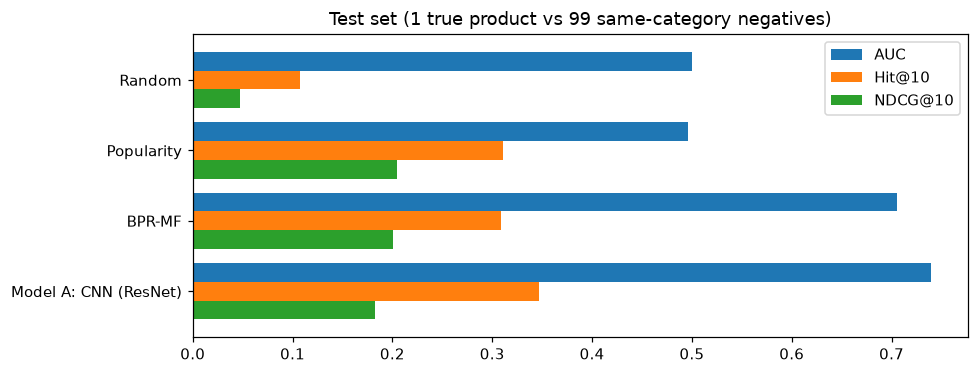

In [10]:
res = pd.DataFrame(results).T
display(res.style.format('{:.3f}').highlight_max(axis=0, color='#c6efce'))
ax = res.plot.barh(figsize=(9, 3.5), width=.8); ax.invert_yaxis(); ax.set_title('Test set (1 true product vs 99 same-category negatives)')
plt.tight_layout(); plt.show()

### Efficiency
The encoder runs once per image (the features can be pre-computed), and the Visual BPR head is tiny. So most of the cost is in the encoder.

In [11]:
eff = pd.DataFrame({k: json.load(open(f'data/encoder_{t}.json')) for k, t in [('Model A: CNN', 'cnn'), ('Model B: Transformer', 'vit')]}).T
eff[['arch', 'params_M', 'input_px', 'embed_dim', 'images_per_sec']]

,arch,params_M,input_px,embed_dim,images_per_sec
Model A: CNN,RN101,56.3,224,512,39.4
Model B: Transformer,ViT-B-32,87.8,224,512,145.4


### Where does each model win? (Hit@10 by category)

In [12]:
ranks = {'Hit@10 CNN': rank_A}
if rank_B is not None: ranks['Hit@10 Transformer'] = rank_B
by = test.assign(**{k: r < 10 for k, r in ranks.items()},
                 product=np.where(test.p.isin(train_products), 'product seen in train', 'unseen product'))
pd.concat([by.groupby('category')[list(ranks)].mean().assign(n=by.category.value_counts()),
           by.groupby('product')[list(ranks)].mean().assign(n=by['product'].value_counts())]).round(3)

,Hit@10 CNN,n
Coats & Jackets,0.374,455
Earrings,0.299,147
"Handbags, Wallets & Cases",0.324,649
Necklaces,0.130,100
Pants,0.334,1505
Shirts & Tops,0.347,1217
Shoes,0.392,2545
Shorts,0.244,308
Skirts,0.357,157
Sunglasses,0.275,418


## 6. Error analysis

The helper below shows a query scene (product greyed out) and a model's top-5 recommendations. The true product is outlined in green.

In [13]:
def show_recs(score_fn, rows, title, top=5):
    df = test.iloc[rows]; cand = np.concatenate([df.p.values[:, None], NEG['test'][rows]], 1)
    sc = score_fn(df, cand)
    fig, ax = plt.subplots(len(rows), top + 1, figsize=(2.1 * (top + 1), 2.3 * len(rows)))
    for i in range(len(rows)):
        r = df.iloc[i]; im = img(r.scene); w, h = im.size; l, t, rr, b = r.bbox
        ax[i, 0].imshow(im); ax[i, 0].add_patch(plt.Rectangle((l*w, t*h), (rr-l)*w, (b-t)*h, color='grey'))
        ax[i, 0].set_title(f'query: {r.category}', fontsize=8)
        for j, k in enumerate(np.argsort(-sc[i])[:top]):
            ax[i, j + 1].imshow(img(idx['products'][cand[i, k]]))
            if k == 0:
                for s in ax[i, j + 1].spines.values(): s.set(color='green', lw=4)
        for a in ax[i]: a.set_xticks([]); a.set_yticks([])
    fig.suptitle(title); plt.tight_layout(); plt.show()

pick = lambda mask, n=3: np.random.default_rng(4).choice(np.where(mask)[0], n, replace=False)

### 6a. Model A (CNN): where it fails
Test scenes where the CNN ranks the true product **outside its top 10**. Once Model B exists, `pick((rank_A >= 10) & (rank_B < 3))` shows the cases the Transformer gets right instead.

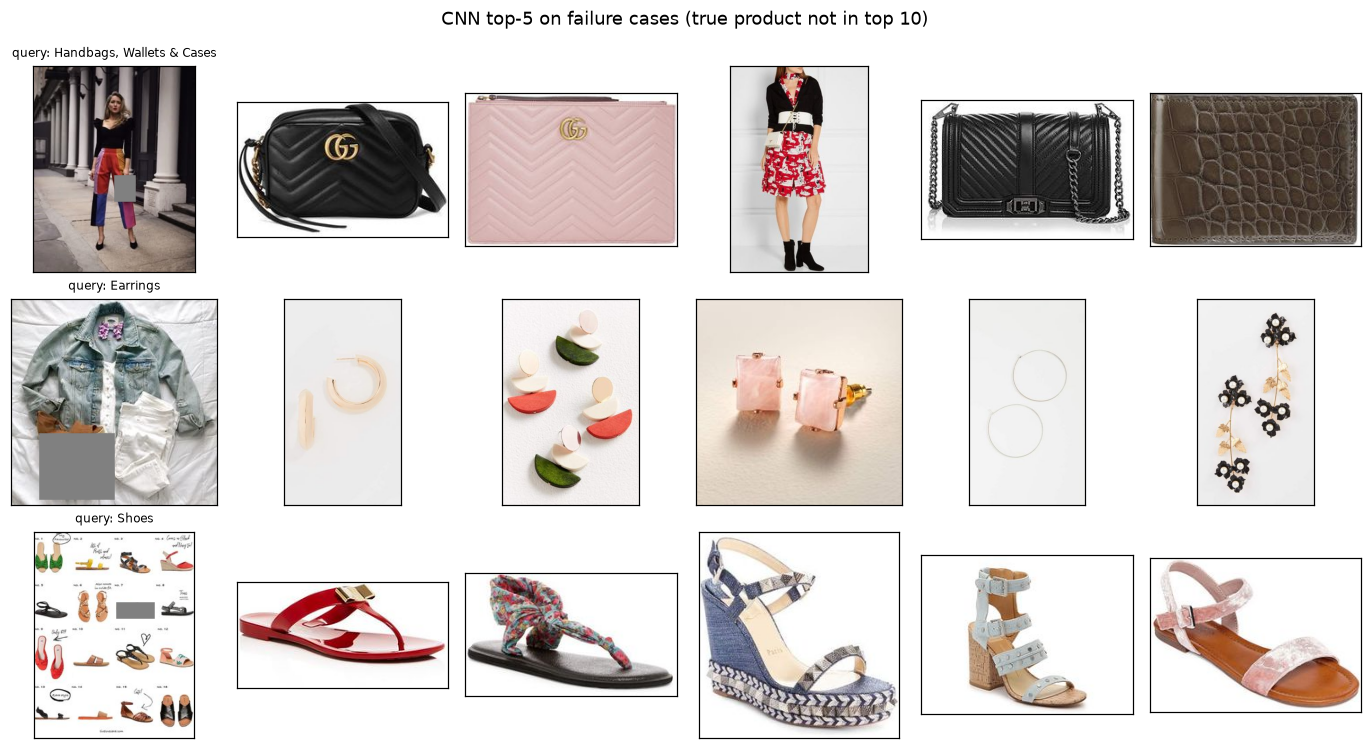

In [14]:
show_recs(score_A, pick(rank_A >= 10), 'CNN top-5 on failure cases (true product not in top 10)')

*Observations (Model A):* to be filled in. For example: does the CNN focus on colour and texture and ignore the overall style of the outfit?

### 6b. Model B (Transformer): *template for the teammate*
Use `show_recs(score_B, pick(rank_B >= 10), ...)` for the Transformer's failure cases, and `pick((rank_B >= 10) & (rank_A < 3))` for cases where the CNN wins.

In [15]:
# TODO (teammate): error analysis for Model B
if score_B is not None:
    show_recs(score_B, pick(rank_B >= 10), 'Transformer top-5 on failure cases')

## 7. Related work

* **Complete the Look** (Kang et al., CVPR 2019) introduced this dataset. It combines global and *local* (region-level attention) compatibility on ResNet features, and evaluates with AUC and Hit@K against same-category negatives.
* **VBPR** (He & McAuley, AAAI 2016) adds visual features to BPR. Our recommender head follows this design.
* **BPR** (Rendle et al., UAI 2009): pairwise ranking from implicit feedback.
* **CNN vs. Transformer encoders:** ResNet (He et al., CVPR 2016), ViT (Dosovitskiy et al., ICLR 2021), and CLIP pre-training (Radford et al., ICML 2021).
* **Industry:** Pinterest's PinSage (Ying et al., KDD 2018) combines visual and text features with the pin–board graph for web-scale recommendation.

---
*Save the headline numbers (used to build the slides).*

In [16]:
summary = {'results': results,
           'hit10_by_category': by.groupby('category')['Hit@10 CNN'].mean().round(4).to_dict(),
           'encoders': {t: json.load(open(f'data/encoder_{t}.json')) for t in ['cnn', 'vit']}}
json.dump(summary, open('results_summary.json', 'w'), indent=1)